# FinTrust Digital Bank: Week 3 Python Analysis
**Track:** Data Analytics | **Author:** Yawa Jacqueline GBEDEVI | **Programme:** AnalystLab Africa

This notebook adds **5 new charts** to the Week 2 analysis. Each chart checks one Week 2 finding or answers a new question.

| Chart | Question | Week 2 link |
|---|---|---|
| 1 | Is Premium really the lowest segment? | Finding 1 |
| 2 | Is the Mobile App really the least reliable channel? | Finding 2 |
| 3 | Is activity growing or falling over the quarter? | Week 2 monthly trend |
| 4 | Do international and high amounts increase the flag rate? | Finding 4 |
| 5 | Does the transaction type matter for the flag rate? | New |

All data is synthetic. `Risk_Review_Flag` is an educational label, not a real fraud determination.

## Step 0: Load the data and check it

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Read the two cleaned sheets
transactions = pd.read_excel("FinTrust_Data.xlsx", sheet_name="FinTrust_Transaction_Data_Clean")
customers = pd.read_excel("FinTrust_Data.xlsx", sheet_name="FinTrust_Customer_Data_Clean")
print("Rows read:", len(transactions))

# Remove the 5 empty rows found in Week 3 (they have no Transaction_ID)
transactions = transactions.dropna(subset=["Transaction_ID"])
print("Rows after cleaning:", len(transactions), "(expected 12000)")

# Join each transaction to its customer (to get the segment, etc.)
df = transactions.merge(customers, on="Customer_ID")
print("Rows after joining:", len(df))

Rows read: 12005
Rows after cleaning: 12000 (expected 12000)
Rows after joining: 12000


## Chart 1: Average and median amount by segment (Finding 1)
Week 2 said Premium had the lowest average. Here the average is shown next to the **median** (the middle value), which is less affected by a few very large amounts.

                     mean   median
Customer_Segment                  
Everyday          46325.0   9929.0
Premium           45638.0  10219.0
SME               49116.0  11627.0
Student           46953.0  10531.0


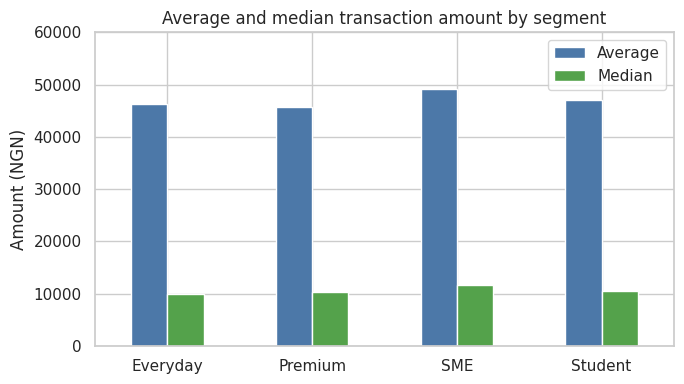

In [2]:
by_segment = df.groupby("Customer_Segment")["Amount_NGN"].agg(["mean", "median"]).round(0)
print(by_segment)

by_segment.plot(kind="bar", figsize=(7, 4), color=["#4C78A8", "#54A24B"])
plt.title("Average and median transaction amount by segment")
plt.ylabel("Amount (NGN)")
plt.xlabel("")
plt.xticks(rotation=0)
plt.ylim(0, 60000)
plt.legend(["Average", "Median"], loc="upper right")
plt.tight_layout()
plt.savefig("figures/chart1_segments.png", dpi=150)
plt.show()

**Reading.** On the average, Premium is the lowest (45,638). On the median, Premium (10,219) is higher than Everyday (9,929). The ranking changes depending on the measure, and the gaps are small. **Finding 1 is revised:** the four segments behave in a similar way, and the data does not show that Premium customers transact less.

## Chart 2: Failure rate by channel (Finding 2)
The failure rate is the share of transactions with status `Failed`. The number of failed transactions is added, because a small rate on a large channel still affects many customers.

            transactions  failed  failure_rate_%
Channel                                         
Mobile App          5102     296            5.80
USSD                 889      48            5.40
POS                 2393     125            5.22
Web                 1869      88            4.71
ATM                 1747      73            4.18


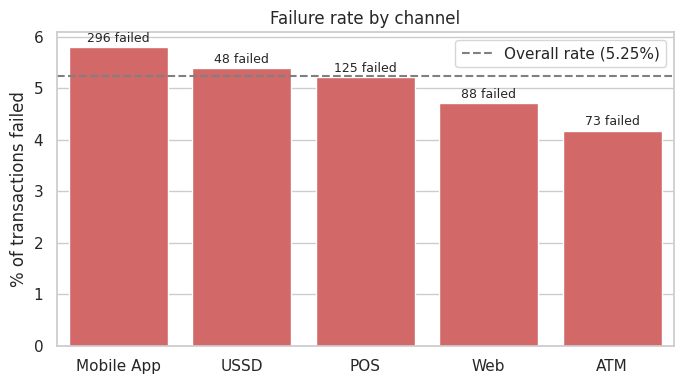

In [3]:
df["is_failed"] = (df["Transaction_Status"] == "Failed").astype(int)

channels = df.groupby("Channel").agg(transactions=("is_failed", "size"), failed=("is_failed", "sum"))
channels["failure_rate_%"] = (channels["failed"] / channels["transactions"] * 100).round(2)
channels = channels.sort_values("failure_rate_%", ascending=False)
print(channels)

overall = df["is_failed"].mean() * 100

plt.figure(figsize=(7, 4))
ax = sns.barplot(x=channels.index, y=channels["failure_rate_%"], color="#E45756")
ax.axhline(overall, color="grey", linestyle="--", label=f"Overall rate ({overall:.2f}%)")
for i, (rate, n) in enumerate(zip(channels["failure_rate_%"], channels["failed"])):
    ax.text(i, rate + 0.1, f"{n} failed", ha="center", fontsize=9)
plt.title("Failure rate by channel")
plt.ylabel("% of transactions failed")
plt.xlabel("")
plt.legend()
plt.tight_layout()
plt.savefig("figures/chart2_channels.png", dpi=150)
plt.show()

**Reading.** The Mobile App has the highest rate (5.80%) and by far the most failed transactions (296), because it carries 42.5% of all traffic. The other channels are between 4.2% and 5.4%, so the gaps in rate are small. **Finding 2 is nuanced:** the Mobile App is where the largest number of customers is affected, but the data does not prove that it is much less reliable than the other channels.

## Chart 3: Transactions per day (trend)
Week 2 compared monthly totals. February looked lower, but it has fewer days. Here activity is shown **per day**, with a 7-day average to smooth the line.

Average transactions per day: 133.3


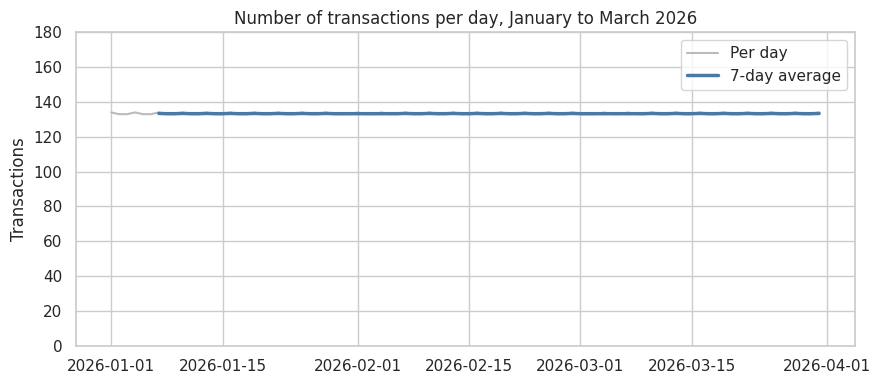

In [4]:
df["Transaction_DateTime"] = pd.to_datetime(df["Transaction_DateTime"])
df["date"] = df["Transaction_DateTime"].dt.date

per_day = df.groupby("date").size()
per_day.index = pd.to_datetime(per_day.index)
average_7_days = per_day.rolling(7).mean()

print("Average transactions per day:", round(per_day.mean(), 1))

plt.figure(figsize=(9, 4))
plt.plot(per_day.index, per_day, color="#BBBBBB", label="Per day")
plt.plot(average_7_days.index, average_7_days, color="#4C78A8", linewidth=2.5, label="7-day average")
plt.ylim(0, 180)
plt.title("Number of transactions per day, January to March 2026")
plt.ylabel("Transactions")
plt.legend()
plt.tight_layout()
plt.savefig("figures/chart3_trend.png", dpi=150)
plt.show()

**Reading.** The line is flat at about 133 transactions per day for the whole quarter. The lower February total in Week 2 only came from the shorter month (28 days), and there is no real dip or rebound. Three months is also too short to talk about growth. Note: a perfectly flat line is unusual in real banking data. It is a limit of the synthetic dataset.

## Chart 4: Flag rate by amount band, domestic versus international (Finding 4)
The flag rate is the share of transactions with `Risk_Review_Flag = Yes`. The amounts are split into 4 bands, using the 117,923 NGN outlier threshold from the Data Quality Report.

             Domestic  International
amount_band                         
Under 10k        16.9           34.1
10k-50k          16.9           40.7
50k-118k         18.2           29.2
Over 118k        31.6           48.1


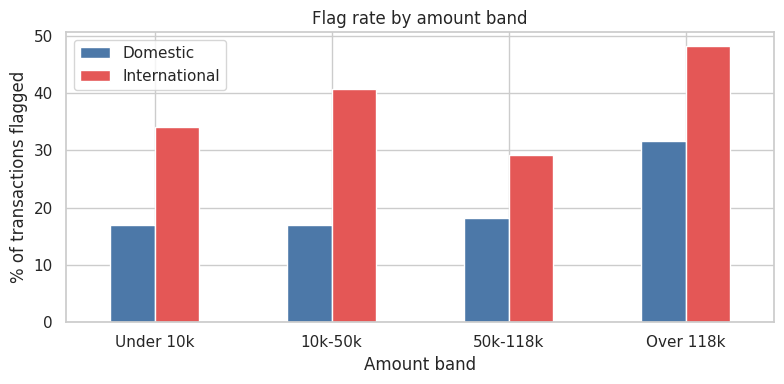

In [5]:
df["is_flagged"] = (df["Risk_Review_Flag"] == "Yes").astype(int)

df["amount_band"] = pd.cut(df["Amount_NGN"],
                           bins=[0, 10000, 50000, 117922.86, float("inf")],
                           labels=["Under 10k", "10k-50k", "50k-118k", "Over 118k"])

by_band = df.pivot_table(index="amount_band", columns="International_Transaction",
                         values="is_flagged", aggfunc="mean", observed=True) * 100
by_band.columns = ["Domestic", "International"]
print(by_band.round(1))

by_band.plot(kind="bar", figsize=(8, 4), color=["#4C78A8", "#E45756"])
plt.title("Flag rate by amount band")
plt.ylabel("% of transactions flagged")
plt.xlabel("Amount band")
plt.xticks(rotation=0)
plt.legend(title="")
plt.tight_layout()
plt.savefig("figures/chart4_flag_by_band.png", dpi=150)
plt.show()

**Reading.** In every amount band, international transactions are flagged much more often than domestic ones (between 1.5 and 2.4 times more). The amount also matters: above 118k, even domestic transactions reach about 32%. The highest rate (48%) combines both. **Finding 4 is confirmed.** Caution: there are few international transactions (480 in total), so each international bar is less precise.

## Chart 5: Flag rate by transaction type (new)
Is the flag rate the same for every type of transaction?

Transaction_Type
Transfer           28.5
Cash Withdrawal    25.3
Deposit            16.2
Airtime/Data       15.2
Card Purchase      13.0
Bill Payment       12.8
Name: is_flagged, dtype: float64


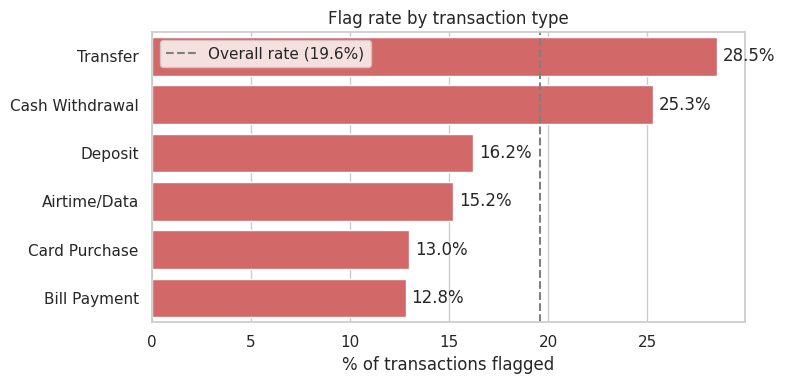

In [6]:
by_type = (df.groupby("Transaction_Type")["is_flagged"].mean() * 100).sort_values(ascending=False).round(1)
print(by_type)

plt.figure(figsize=(8, 4))
ax = sns.barplot(x=by_type.values, y=by_type.index, color="#E45756")
ax.axvline(df["is_flagged"].mean() * 100, color="grey", linestyle="--", label="Overall rate (19.6%)")
for i, v in enumerate(by_type.values):
    ax.text(v + 0.3, i, f"{v}%", va="center")
plt.title("Flag rate by transaction type")
plt.xlabel("% of transactions flagged")
plt.ylabel("")
plt.legend()
plt.tight_layout()
plt.savefig("figures/chart5_flag_by_type.png", dpi=150)
plt.show()

**Reading.** Transfer (28.5%) and Cash Withdrawal (25.3%) are flagged about twice as often as Card Purchase, Bill Payment, Deposit or Airtime/Data (about 13 to 16%). Part of this could come from larger amounts, but in a separate check by amount band, the gap remained inside each band. Transaction type is therefore a **third factor** linked to the flag, in addition to international status and amount. This is new compared with Week 2.

## Optional check: do the differences come from chance?
These 3 lines give a p-value. A p-value **below 0.05** means the difference is unlikely to be only chance. You can quote the results in one sentence in your report, or skip this cell.

In [7]:
from scipy import stats

# 1. Do amounts differ between segments?
groups = [g["Amount_NGN"] for _, g in df.groupby("Customer_Segment")]
print("Segments (amounts), p-value:", round(stats.kruskal(*groups).pvalue, 2))

# 2. Does the failure rate differ between channels?
table = pd.crosstab(df["Channel"], df["is_failed"])
print("Channels (failure rate), p-value:", round(stats.chi2_contingency(table)[1], 3))

Segments (amounts), p-value: 0.2
Channels (failure rate), p-value: 0.081


**Reading.** Both p-values are above 0.05 (about 0.20 and 0.08). The differences between segments and between channels could come from chance, which supports revising Finding 1 and nuancing Finding 2.

## Summary of the Week 2 findings

| Week 2 finding | Result after Week 3 |
|---|---|
| 1. Premium has the lowest transaction value | **Revised:** segments behave similarly (Chart 1) |
| 2. Mobile App is the most valuable and least reliable channel | **Nuanced:** most failures in number, but rates are close (Chart 2) |
| 3. Transfer and Card Purchase are over half of activity | Confirmed (54.9%, from the SQL analysis) |
| 4. Flagging follows an explainable pattern | **Confirmed and extended** with transaction type (Charts 4 and 5) |
| 5. Amounts are skewed with a long tail of large values | Confirmed (average 46,706 versus median 10,306) |

## Limitations
- The data is synthetic, so patterns are simpler and more regular than real banking data (flat daily activity, for example).
- Only 3 months of data: no growth or seasonality can be measured.
- There are few international transactions (480), so international results are less precise.